# Neural-to-Text EEG Decoding with a Spiking Neural Network

**Goal:** classify a short EEG feature window into one of a small set of word/utterance labels, then decode the class as text.

This notebook is a constrained-vocabulary engineering prototype. It is not an unrestricted brain-to-text language model. The first run uses synthetic data to verify the complete workflow; replace it with properly prepared, ethically sourced EEG features for research.

## 1. Imports and reproducibility

In [1]:
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

import torch
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")  # Deliberately CPU-first
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.15.0+cpu
Device: cpu


## 2. Load a dataset (synthetic demo by default)

Each row represents one EEG trial/window and each numeric column is a feature. For a real experiment, features might be channel-wise band powers, log-variance, or a fixed-length window representation.

In [2]:
USE_SYNTHETIC_DEMO = True
CSV_PATH = "../data/eeg_features.csv"  # Set USE_SYNTHETIC_DEMO=False to use this file
LABEL_COLUMN = "label"

if USE_SYNTHETIC_DEMO:
    # Toy data only: class-dependent feature patterns make the pipeline testable.
    # These values are NOT EEG recordings and cannot support scientific claims.
    rng = np.random.default_rng(SEED)
    labels = np.array(["yes", "no", "stop", "go"])
    n_per_class, n_features = 180, 24
    centers = rng.normal(0, 0.7, size=(len(labels), n_features))
    rows, targets = [], []
    for class_id, label in enumerate(labels):
        class_rows = centers[class_id] + rng.normal(0, 0.85, size=(n_per_class, n_features))
        rows.append(class_rows)
        targets.extend([label] * n_per_class)
    X_df = pd.DataFrame(np.vstack(rows), columns=[f"eeg_feature_{i:02d}" for i in range(n_features)])
    X_df[LABEL_COLUMN] = targets
else:
    raw = pd.read_csv(CSV_PATH)
    if LABEL_COLUMN not in raw.columns:
        raise ValueError(f"Expected a target column named {LABEL_COLUMN!r}")
    X_df = raw.copy()

display(X_df.head())
print("Rows:", len(X_df), "| Classes:", X_df[LABEL_COLUMN].nunique())

,eeg_feature_00,eeg_feature_01,eeg_feature_02,eeg_feature_03,eeg_feature_04,eeg_feature_05,eeg_feature_06,eeg_feature_07,eeg_feature_08,eeg_feature_09,...,eeg_feature_15,eeg_feature_16,eeg_feature_17,eeg_feature_18,eeg_feature_19,eeg_feature_20,eeg_feature_21,eeg_feature_22,eeg_feature_23,label
0,-0.910993,-1.575649,0.865124,-0.111262,-1.687163,0.192818,-0.213336,0.405518,-0.805336,-0.771753,...,-0.399429,-0.246902,-1.900367,0.676225,-0.485017,0.068371,-0.458076,2.217291,-0.311623,yes
1,-0.656671,-0.575605,0.712313,1.813705,-0.655880,-0.608185,1.333296,-1.231818,-0.555550,-1.384720,...,-1.464747,0.524612,0.041190,2.312136,2.441835,0.222844,-1.317758,-0.956460,0.119384,yes
2,-0.477698,-1.081043,0.005034,0.538723,-0.459641,-0.778034,-0.045351,-1.101676,-1.435241,-1.010492,...,-1.608707,-0.562224,-1.287660,2.424114,-0.733127,0.583312,-1.244139,1.647616,0.219038,yes
3,0.080160,-0.762637,-0.031254,1.037557,-1.752461,-1.953291,-0.996759,-0.074670,1.330467,-0.461138,...,0.338841,0.622569,0.634175,0.770664,-1.075747,-1.292339,0.926638,2.320895,-0.260762,yes
4,-0.112407,0.514239,-0.415673,-0.102123,-0.818897,-1.246940,0.085135,-0.360296,0.275178,0.599229,...,-1.637496,-0.488304,-0.955223,1.393432,-1.162382,-0.103367,-0.888195,0.577257,0.744174,yes


Rows: 720 | Classes: 4


## 3. Prepare features and labels

The scaler is fitted only on the training partition to avoid leakage. For real EEG, replace the random row split with a participant/session-grouped split whenever metadata allows.

In [3]:
feature_columns = X_df.select_dtypes(include=[np.number]).columns.tolist()
if not feature_columns:
    raise ValueError("No numeric EEG feature columns found.")

X = X_df[feature_columns].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True)).to_numpy(dtype=np.float32)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(X_df[LABEL_COLUMN].astype(str))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

X_train_t = torch.tensor(X_train, dtype=torch.float32, device=DEVICE)
X_test_t = torch.tensor(X_test, dtype=torch.float32, device=DEVICE)
y_train_t = torch.tensor(y_train, dtype=torch.long, device=DEVICE)
y_test_t = torch.tensor(y_test, dtype=torch.long, device=DEVICE)

n_features = X_train.shape[1]
n_classes = len(label_encoder.classes_)
print("Features:", n_features, "| Classes:", list(label_encoder.classes_))

Features: 24 | Classes: [np.str_('go'), np.str_('no'), np.str_('stop'), np.str_('yes')]


## 4. Encode EEG features as spike trains

A simple rate encoder converts non-negative feature currents into Bernoulli spike events over discrete time steps. This is an engineering baseline, not a claim that biological neurons encode EEG in exactly this way.

In [4]:
def rate_encode(features, time_steps=20, max_rate=0.8):
    # Map standardized features to [0, 1] currents using a bounded transform.
    currents = torch.sigmoid(torch.tensor(features, dtype=torch.float32))
    probabilities = (currents * max_rate).clamp(0.0, 1.0)
    return torch.bernoulli(
        probabilities.unsqueeze(0).repeat(time_steps, 1, 1)
    )

TIME_STEPS = 20
spikes_train = rate_encode(X_train, TIME_STEPS)
spikes_test = rate_encode(X_test, TIME_STEPS)
print("Spike tensor:", tuple(spikes_train.shape), "(time, batch, features)")
print("Mean spike activity:", float(spikes_train.mean()))

Spike tensor: (20, 540, 24) (time, batch, features)
Mean spike activity: 0.4003819525241852


## 5. Build a LIF spiking neural network

The LIF unit integrates input current, leaks its membrane potential over time, emits a spike at threshold, and resets. A smooth surrogate derivative is used during backpropagation because the hard threshold is non-differentiable.

In [5]:
class SurrogateSpike(torch.autograd.Function):
    @staticmethod
    def forward(ctx, membrane_minus_threshold):
        ctx.save_for_backward(membrane_minus_threshold)
        return (membrane_minus_threshold >= 0).float()

    @staticmethod
    def backward(ctx, grad_output):
        (x,) = ctx.saved_tensors
        # Fast-sigmoid surrogate derivative
        scale = 10.0
        grad = 1.0 / (scale * torch.abs(x) + 1.0).pow(2)
        return grad_output * grad

spike_fn = SurrogateSpike.apply


class LIFNetwork(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, beta=0.90, threshold=1.0):
        super().__init__()
        self.input_layer = nn.Linear(input_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, output_size)
        self.beta = beta
        self.threshold = threshold

    def forward(self, spike_sequence):
        batch_size = spike_sequence.shape[1]
        membrane = torch.zeros(batch_size, self.input_layer.out_features, device=spike_sequence.device)
        output_spikes = []
        for step in range(spike_sequence.shape[0]):
            current = self.input_layer(spike_sequence[step])
            membrane = self.beta * membrane + current
            spikes = spike_fn(membrane - self.threshold)
            membrane = membrane * (1.0 - spikes)  # hard reset
            output_spikes.append(self.output_layer(spikes))
        return torch.stack(output_spikes).mean(dim=0)


class ANNBaseline(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, output_size)
        )
    def forward(self, x):
        return self.net(x)

## 6. Train and evaluate both models

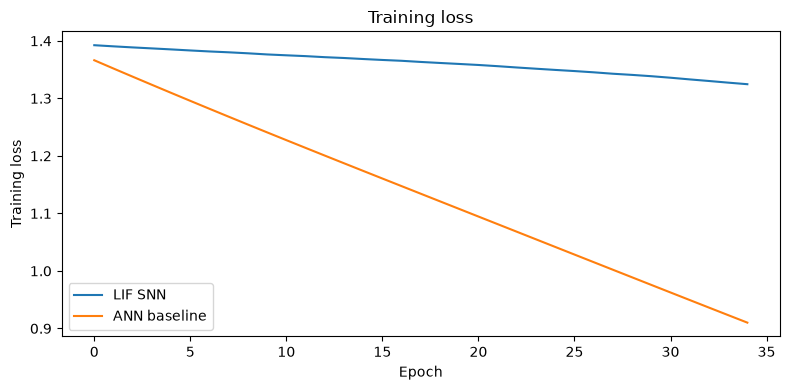

In [6]:
def train_model(model, inputs, targets, epochs=35, learning_rate=1e-3, is_snn=False):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss()
    losses = []
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = model(inputs) if is_snn else model(inputs)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
        losses.append(float(loss.detach()))
    return losses

hidden_size = 48
snn = LIFNetwork(n_features, hidden_size, n_classes)
ann = ANNBaseline(n_features, hidden_size, n_classes)

snn_losses = train_model(snn, spikes_train, y_train_t, is_snn=True)
ann_losses = train_model(ann, X_train_t, y_train_t)

plt.figure(figsize=(8, 4))
plt.plot(snn_losses, label="LIF SNN")
plt.plot(ann_losses, label="ANN baseline")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training loss")
plt.legend()
plt.tight_layout()
plt.show()

### LIF SNN
Accuracy: 0.7
Macro-F1: 0.6691
              precision    recall  f1-score   support

          go       0.79      0.24      0.37        45
          no       0.61      0.89      0.72        45
        stop       0.89      0.73      0.80        45
         yes       0.67      0.93      0.78        45

    accuracy                           0.70       180
   macro avg       0.74      0.70      0.67       180
weighted avg       0.74      0.70      0.67       180

### ANN baseline
Accuracy: 0.9167
Macro-F1: 0.9152
              precision    recall  f1-score   support

          go       0.97      0.78      0.86        45
          no       0.95      0.93      0.94        45
        stop       0.86      0.96      0.91        45
         yes       0.90      1.00      0.95        45

    accuracy                           0.92       180
   macro avg       0.92      0.92      0.92       180
weighted avg       0.92      0.92      0.92       180



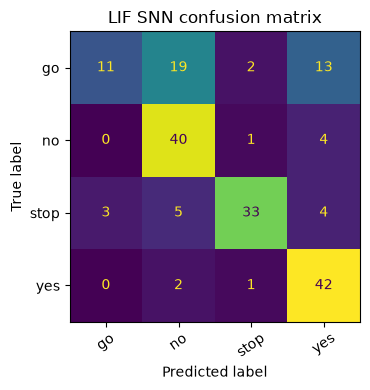

In [7]:
snn.eval()
ann.eval()
with torch.no_grad():
    snn_pred = snn(spikes_test).argmax(dim=1).cpu().numpy()
    ann_pred = ann(X_test_t).argmax(dim=1).cpu().numpy()

def report_model(name, truth, pred):
    print(f"### {name}")
    print("Accuracy:", round(accuracy_score(truth, pred), 4))
    print("Macro-F1:", round(f1_score(truth, pred, average="macro"), 4))
    print(classification_report(
        truth, pred, labels=np.arange(n_classes),
        target_names=label_encoder.classes_, zero_division=0
    ))

report_model("LIF SNN", y_test, snn_pred)
report_model("ANN baseline", y_test, ann_pred)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, snn_pred, display_labels=label_encoder.classes_,
    xticks_rotation=35, ax=ax, colorbar=False
)
ax.set_title("LIF SNN confusion matrix")
plt.tight_layout()
plt.show()

## 7. Decode predicted classes into text

This is the text-decoding stage: the classifier's winning class is mapped back to its vocabulary label. It does not compose new words or sentences.

In [8]:
def decode_to_text(predicted_class_ids):
    return label_encoder.inverse_transform(np.asarray(predicted_class_ids, dtype=int))

decoded = decode_to_text(snn_pred[:12])
for index, text_label in enumerate(decoded, start=1):
    print(f"Trial {index:02d}: {text_label}")

Trial 01: no
Trial 02: yes
Trial 03: no
Trial 04: no
Trial 05: yes
Trial 06: yes
Trial 07: no
Trial 08: yes
Trial 09: yes
Trial 10: yes
Trial 11: no
Trial 12: stop


## 8. Neuromorphic activity and inference timing

Spike count and firing rate are simple activity proxies. Wall-clock timing on a shared CPU notebook is noisy; use repeated measurements and a controlled environment for hardware comparisons.

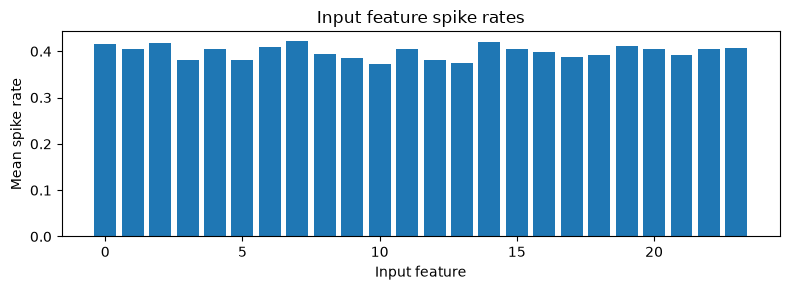

Median full-test-batch SNN forward pass: 5.475 ms
Median full-test-batch ANN forward pass: 0.138 ms


In [9]:
spike_count = spikes_test.sum(dim=0).numpy()
firing_rate_per_feature = spikes_test.mean(dim=(0, 1)).numpy()

plt.figure(figsize=(8, 3))
plt.bar(np.arange(len(firing_rate_per_feature)), firing_rate_per_feature)
plt.xlabel("Input feature")
plt.ylabel("Mean spike rate")
plt.title("Input feature spike rates")
plt.tight_layout()
plt.show()

def benchmark(callable_fn, repeats=30):
    durations = []
    for _ in range(repeats):
        start = time.perf_counter()
        callable_fn()
        durations.append(time.perf_counter() - start)
    return float(np.median(durations) * 1000)

with torch.no_grad():
    snn_ms = benchmark(lambda: snn(spikes_test))
    ann_ms = benchmark(lambda: ann(X_test_t))
print(f"Median full-test-batch SNN forward pass: {snn_ms:.3f} ms")
print(f"Median full-test-batch ANN forward pass: {ann_ms:.3f} ms")

## 9. Research checklist for a real EEG study

Before interpreting results, document:

- Dataset source, access date, license, and citation.
- Task paradigm (spoken, attempted speech, imagined speech, or reading).
- Sampling rate, channel montage, reference, filtering, and artifact rejection.
- Window duration and alignment between EEG and text labels.
- Participant-independent or session-independent evaluation.
- Class balance, number of participants, and uncertainty intervals.
- Baseline models and compute/hardware used.

### Next engineering extensions

1. Add raw-signal preprocessing with MNE-Python (filtering, epoching, artifact handling).
2. Add subject-wise cross-validation and per-participant metrics.
3. Compare rate coding with latency/temporal coding.
4. Export a quantized model and benchmark on a neuromorphic-compatible runtime/hardware target.
5. Evaluate energy and latency on actual hardware; do not infer energy efficiency from spike sparsity alone.

**Responsible use:** EEG is sensitive personal data. Obtain informed consent, follow dataset terms and applicable law, protect participant identity, and do not use this demo for clinical or safety-critical decisions.